In [10]:
# Importa bibliotecas
import matplotlib.pyplot as plt
import numpy as np
import csv
from scipy.signal import argrelextrema

In [11]:
# abrimos el archivo y obtenemos las columnas que nos itneresan
# Se baso en la siguiente pagina web: https://realpython.com/python-csv/
def leer_archivo(nombre):
    #Hay que analizar las primeras 3 renglones por separado.
    #delta[0], delta[-1] seran los extremos del intervalo en Hz
    
    arch = open(nombre, "r")
    if arch.mode != 'r':
        print("No existe el archivo")
        return []
    
    yy = []
    for line in arch.readlines():
        # Tiene tab al final
        par = np.array(line.split('\t')[:-1], dtype=float)
        yy.append(par)
    yy = np.array(yy)
    #delta = (yy[-1] - yy[0]) * frq_MHz
    delta = (yy[-1] - yy[0]) * 700
    
    return [yy[:,1], delta[0], delta[1]]

In [12]:
def aplicar(x, y, m):
    # El tamaño de x tiene que ser del tamaño de y mas m
    #x y y son arreglos
    x_new = np.copy(x)
    for i in range(0, len(y)):
        x_new[m+i] += y[i]
    return x_new

In [13]:
def convolucion(yy, n = 40, n_deltas = 128): #que n va de 1 hasta 64
    tamano = len(yy)
    ceros = np.zeros(tamano + n*n_deltas)

    mitad = n_deltas//2
    for i in range(0, n_deltas):
        if i < mitad:
            ceros = aplicar(ceros, (-1)**i*yy, n*i)
        else:
            ceros = aplicar(ceros, (-1)**(i+1)*yy, n*i)
    return ceros

In [14]:
#Input: yy
def integrar(yy, intervalo = 60, n_deltas = 8):
    #intervalo es el maximo valor de las n
    
    integrs = np.zeros(intervalo)
    
    for i in range(1, intervalo):
        y_new = convolucion(yy, i, n_deltas)
        integral = sum(abs(y_new))
        integrs[i] = integral
    return integrs

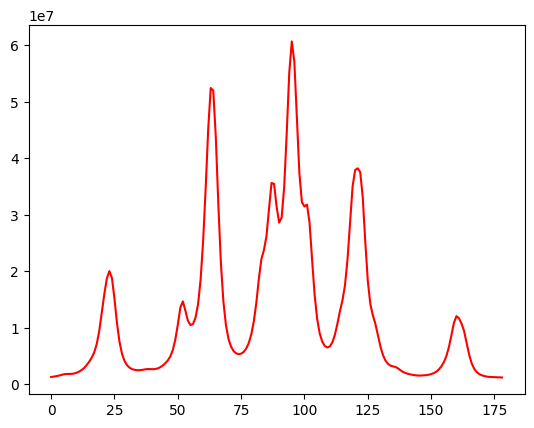

179


In [15]:
frq_MHz = 700
archivo_entrada = '../../assets/mnova-signals/cpto-1111.csv'
archivo_salida = 'oot.csv'
yy, a, b = leer_archivo(archivo_entrada)
yy_orig = yy
# Con escala en enteros
#plt.figure(size=(20,10))
plt.plot(yy, color = "red")
#plt.plot([iz, de], [yy[iz], yy[de]])
plt.show()
print(len(yy))

178


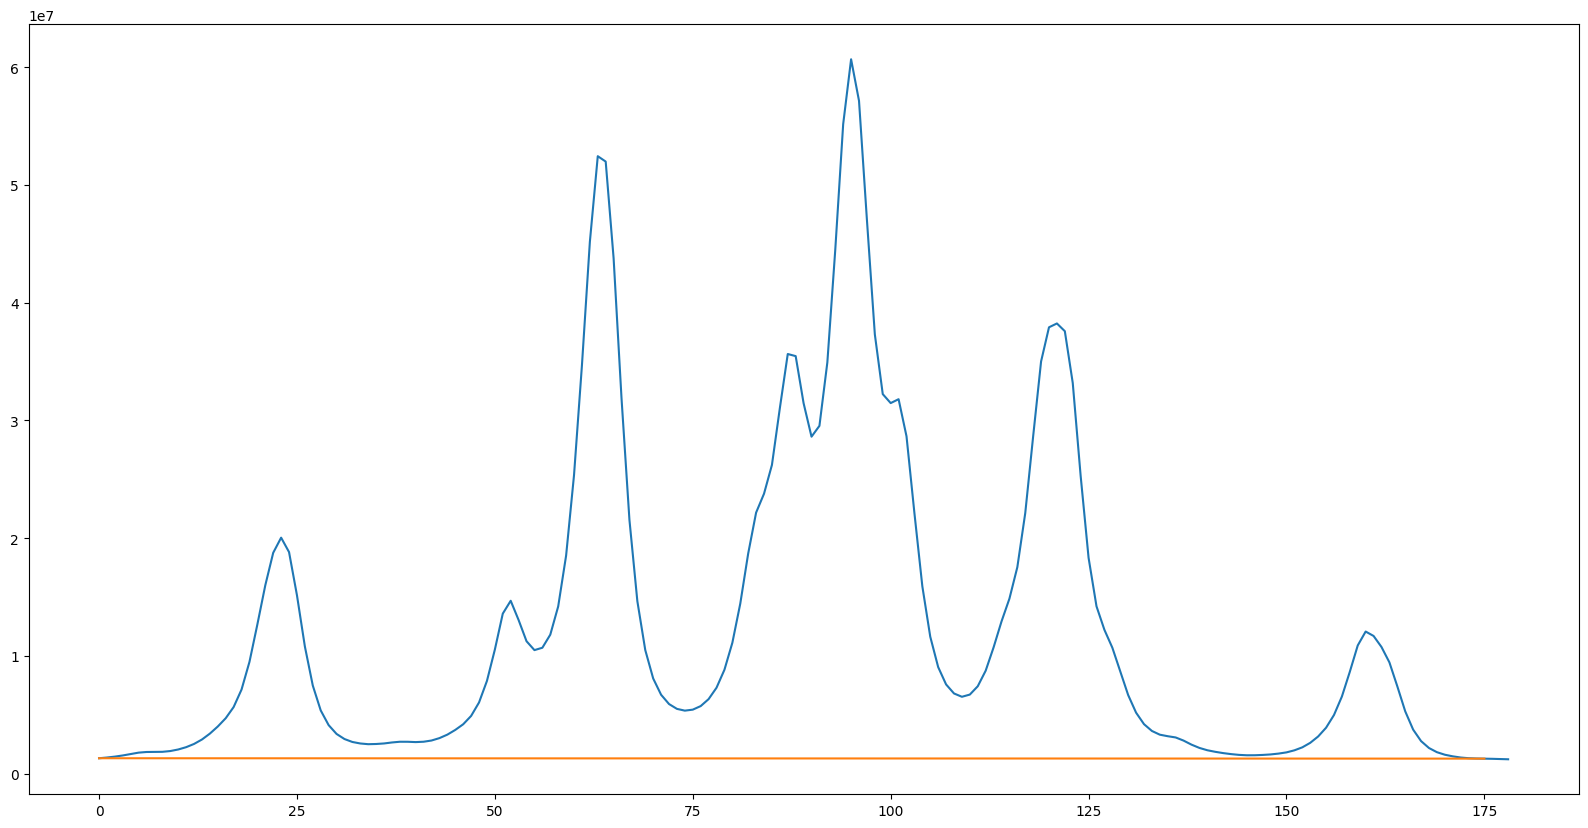

In [16]:
print(list(yy).index(min(yy)))
#Eliminación de regiones sin ajuste de línea base
iz = 0
de = 175
if de > len(yy):
    de = len(yy) - 1
pendiente = (yy[de]-yy[iz])/(de-iz)
ordenada_o = pendiente*iz - yy[iz]
plt.figure(figsize=(20,10))
plt.plot(yy)
plt.plot([iz, de], [yy[iz], yy[de]])

-190.68571428571428 -1315580.0 1282210.0 1315580.0 175 0
Minimo:  0.0


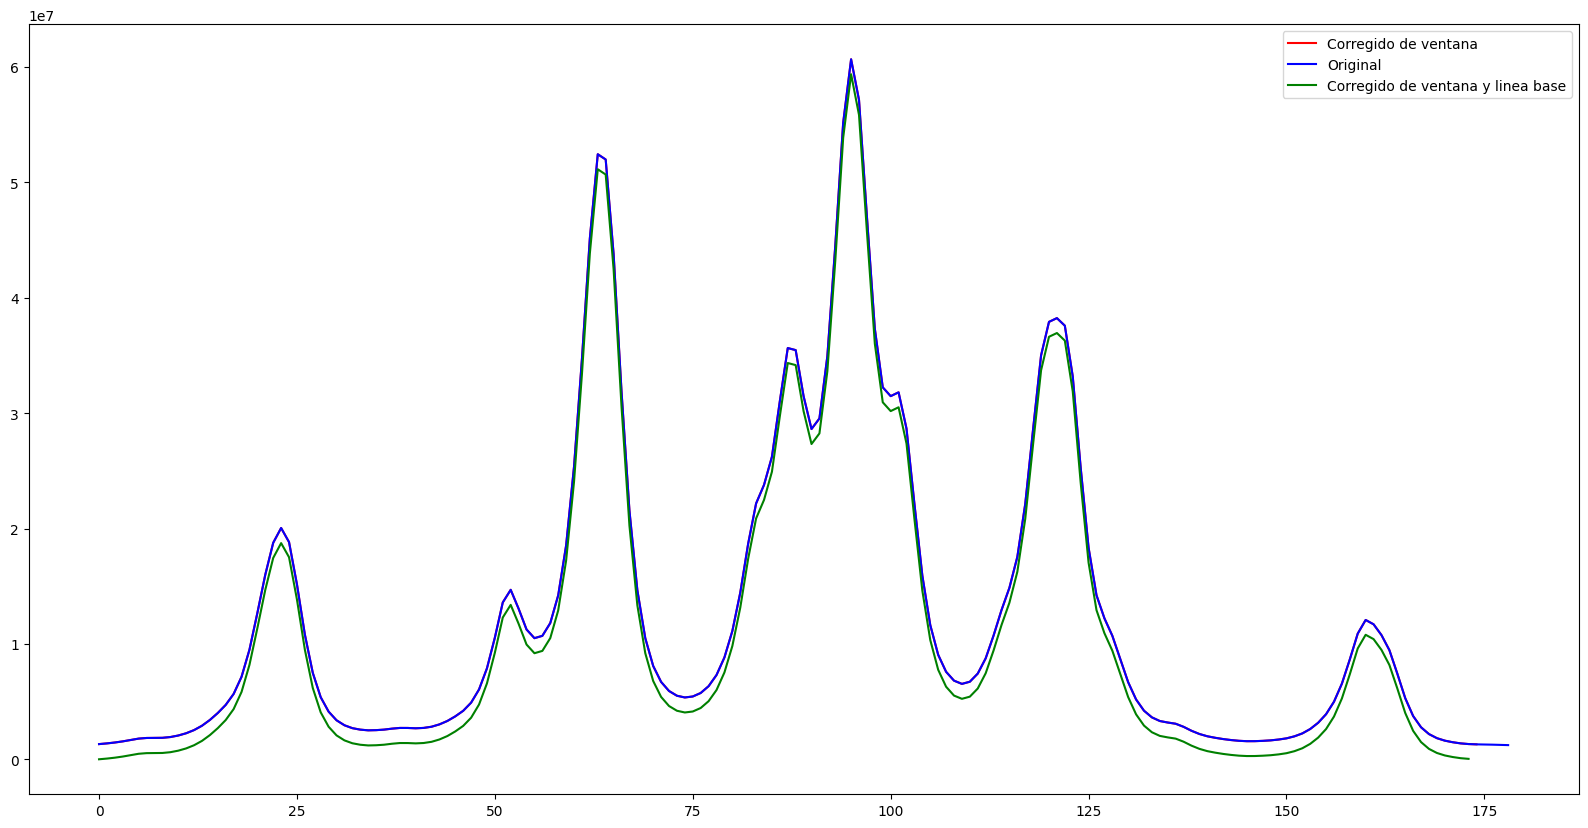

In [17]:
#Reducción de ventana y corrección de línea base"]
pendiente = (yy[de]-yy[iz])/(de-iz)
ordenada_o = pendiente*iz - yy[iz]

print(pendiente,ordenada_o, yy[de],yy[iz],de,iz)

y = np.zeros(de-iz-1)
for i in range(0, de-iz-1):
    y[i] = yy[iz+i] - (pendiente*i-ordenada_o)

print("Minimo: ", min(y))
y = y - min(y)
plt.figure(figsize=(20,10))
plt.plot(yy[iz:de], color = "red")
plt.plot(yy, color = "blue")
plt.plot(y, color = "green")
plt.legend(['Corregido de ventana ',
            'Original',
            'Corregido de ventana y linea base'])
plt.show()
#print(y)

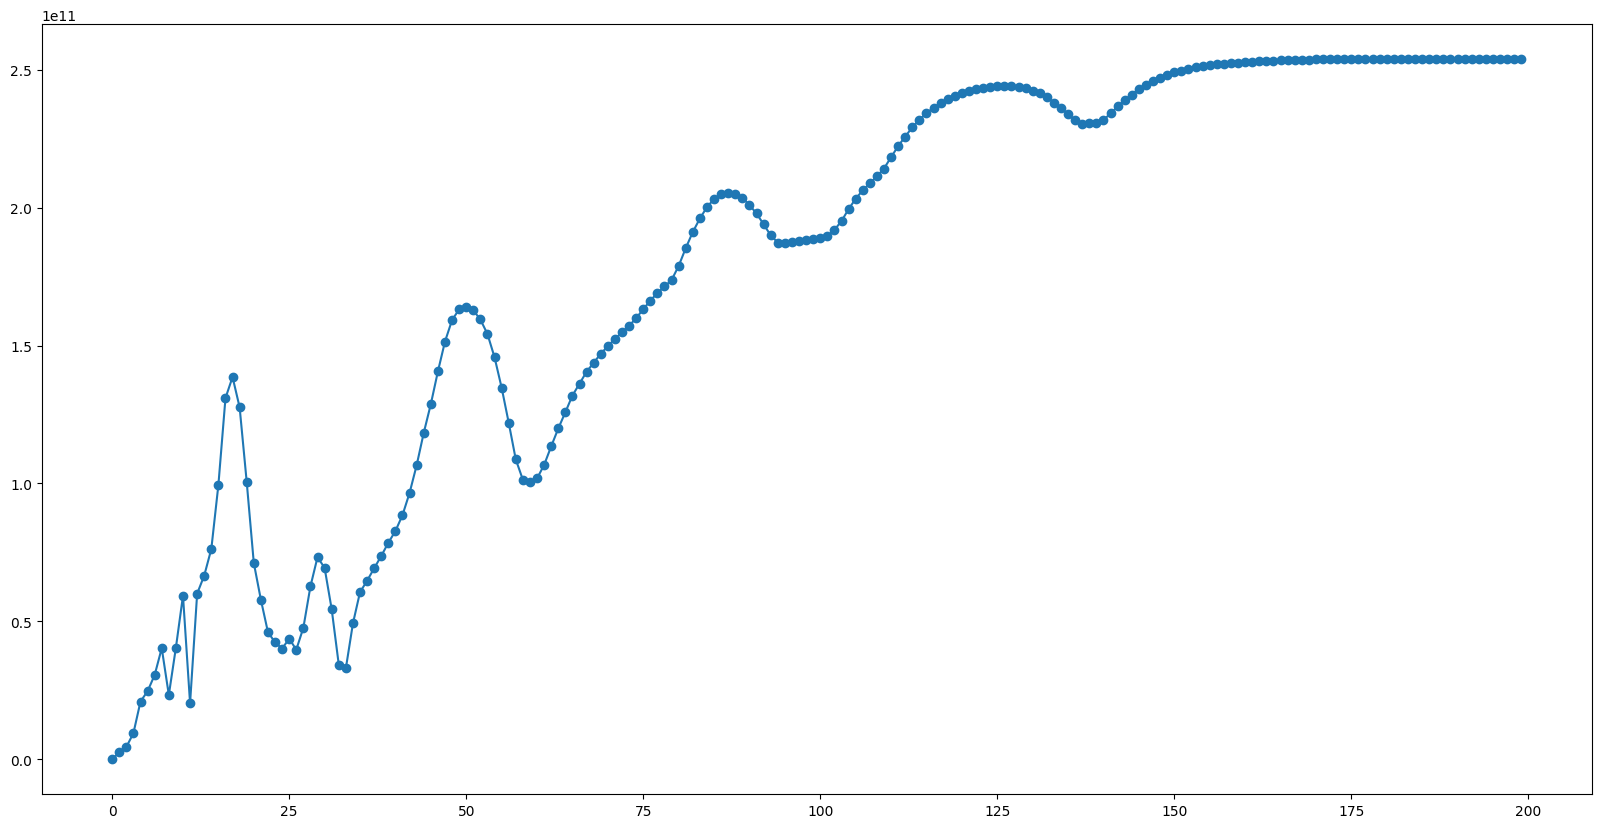

valores maximos en: [  8  11  24  26  33  59  95 137]
Mínimo:  137
res 0.22313966480446884


In [18]:
# Generar la secuencia xx
#relacion_Hz_x_punto = abs(b-a)/len(yy)
relacion_Hz_x_punto = abs(a)/len(yy)
xx = [i*relacion_Hz_x_punto + min([a, b]) for i in range(0, len(yy))]

#Redefiniendo el arreglo en y
yy = yy[iz:de]
xx = xx[iz:de]
#nuevo_paso_hz = (xx[-1]-xx[0])/len(yy)

# La escala en X de la siguiente figura está en enteros. Utilizar paso_Hz para convertir a Hz
intervalo = 200
n_deltas = 128
integrs = integrar(y, intervalo, n_deltas)

plt.figure(figsize=(20,10))
plt.plot(integrs, marker = 'o')
plt.show()

mins = argrelextrema(integrs, np.less)[0]

print("valores maximos en: "+str(argrelextrema(integrs, np.less)[0]))
print("Mínimo: ", mins[-1])
print(f"res {relacion_Hz_x_punto}")

def ppm_to_hz(ppm:float, frequency_mhz:float) -> float:
    "Convert values from ppm to Hz produced by nmr"
    return ppm*frequency_mhz / 10**6



In [19]:
#Seleccionar el mínimoj_estimada deseado para que se determine la J.¶
j_estimada =137
print("Jota: ",  j_estimada*relacion_Hz_x_punto, "        Resolución Digital", relacion_Hz_x_punto,)


Jota:  30.57013407821223         Resolución Digital 0.22313966480446884


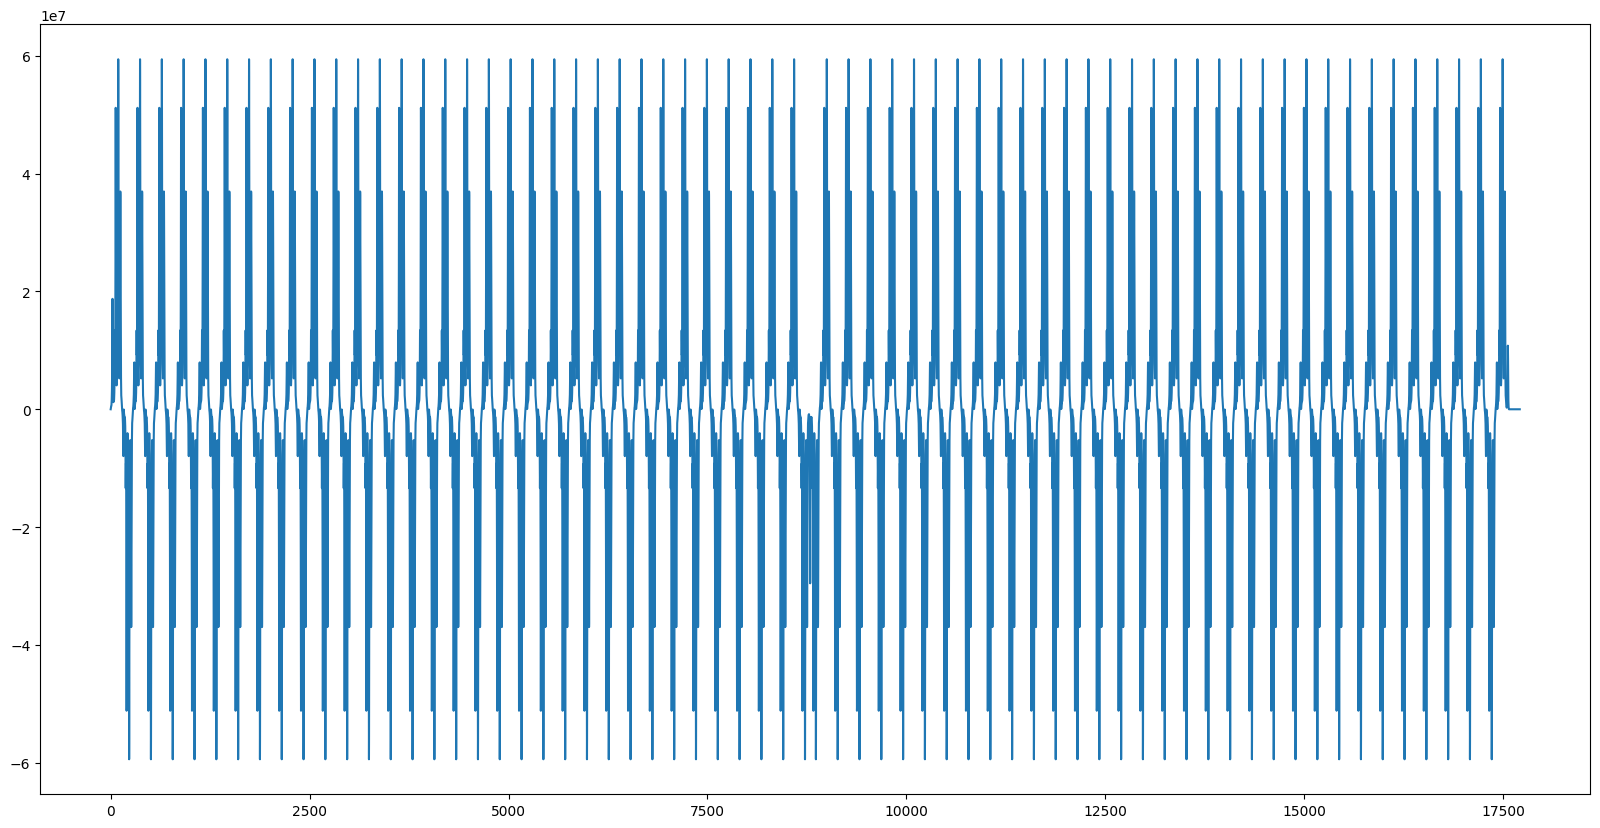

In [20]:
t_desconvolucion = convolucion(y, j_estimada, n_deltas)

plt.figure(figsize=(20,10))
plt.plot(t_desconvolucion)
plt.show()

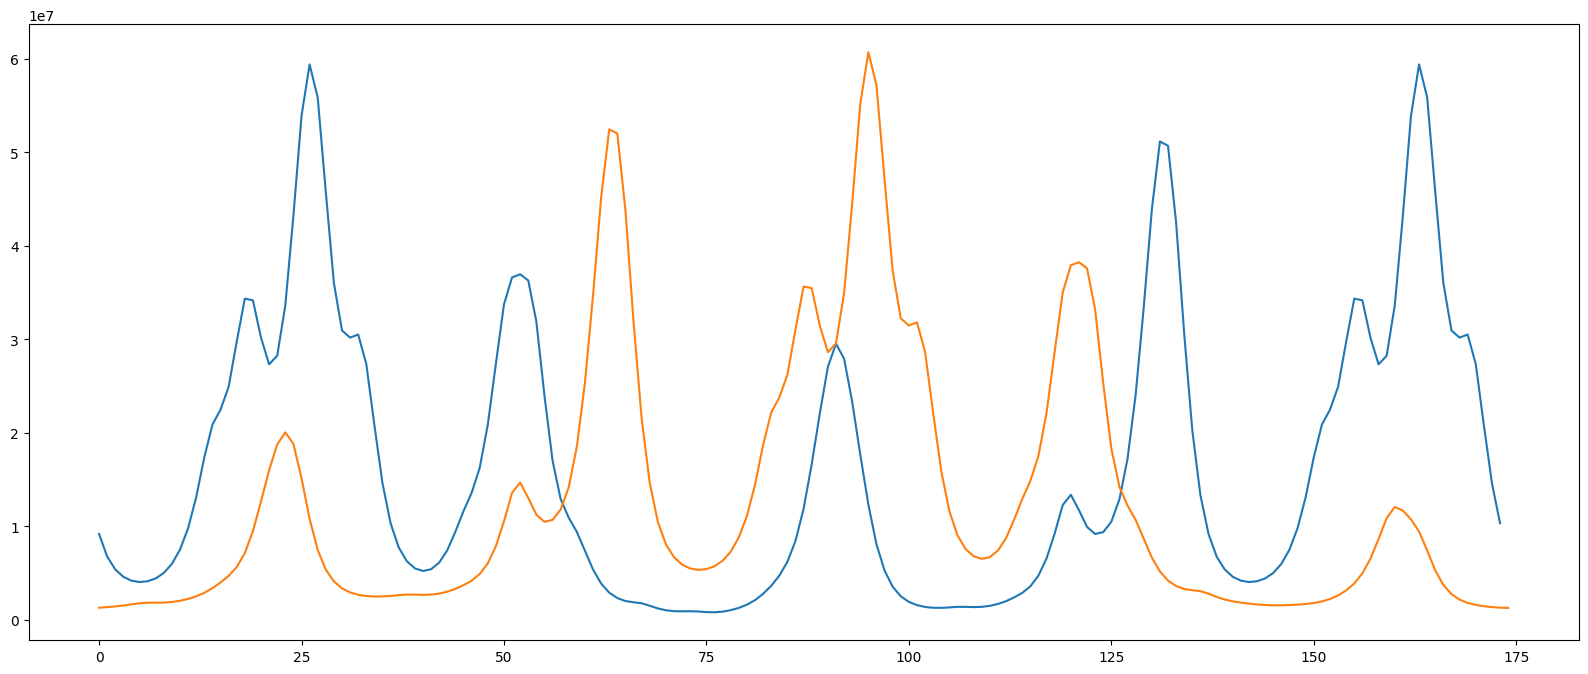

In [21]:
n_puntos = len(yy)//2
mitad = -(j_estimada // 2) + (len(t_desconvolucion)//2)
init = mitad - n_puntos
fin = mitad + n_puntos
t_desconvolucion_centrada = t_desconvolucion[init:fin]*-1

plt.figure(figsize=(20,8))
plt.plot(t_desconvolucion_centrada)
plt.plot(yy)
plt.show()

In [22]:
for i in range(5):
    print(f'{yy_orig[i]}')
print(a)
print(1/a)

1315580.0
1376690.0
1454050.0
1552220.0
1671350.0
39.94199999999992
0.025036302638826346


In [23]:
cad = ''
for i, val in enumerate(t_desconvolucion_centrada):
    cad += f'{i*relacion_Hz_x_punto/frq_MHz}\t{val}\t\n'

arch_guardar = open(archivo_salida, 'w')
arch_guardar.write(cad)
arch_guardar.close()